# IntelliSense Backtest Analysis
Compare the performance of **Fixed Q-table**, **Q-learning**, and **DQN** strategies across different tickers.

---

In [167]:
import pandas as pd
import matplotlib.pyplot as plt
import mplfinance as mpf
import json
import os
import numpy as np
from IPython.display import display, Markdown, HTML

def compute_metrics(trades_df, stock_df):
    """Compute Max DD, Alpha (vs S&P 500), Sharpe Ratio, and Win Rate."""
    
    portfolio_values = trades_df['portfolio_value'].values
    
    # --- Max Drawdown ---
    running_max = np.maximum.accumulate(portfolio_values)
    drawdowns = (running_max - portfolio_values) / running_max
    max_dd = np.max(drawdowns) * 100
    
    # --- Total Return ---
    initial_val = portfolio_values[0]
    final_val = portfolio_values[-1]
    total_return = (final_val - initial_val) / initial_val
    
    # --- Alpha (vs S&P 500 benchmark) ---
    dates = pd.to_datetime(trades_df['date'])
    n_years = (dates.iloc[-1] - dates.iloc[0]).days / 365.25
    sp500_annual_return = 0.10
    sp500_period_return = (1 + sp500_annual_return) ** n_years - 1
    alpha = (total_return - sp500_period_return) * 100
    
    # --- Sharpe Ratio (annualized, weekly data, 0% risk-free) ---
    weekly_returns = np.diff(portfolio_values) / portfolio_values[:-1]
    if np.std(weekly_returns) > 0:
        sharpe = (np.mean(weekly_returns) / np.std(weekly_returns)) * np.sqrt(52)
    else:
        sharpe = 0.0
    
    # --- Win Rate (only count trades where shares > 0) ---
    real_buys = trades_df[(trades_df['action'] == 'BUY') & (trades_df['shares'] > 0)]
    real_sells = trades_df[(trades_df['action'] == 'SELL') & (trades_df['shares'] > 0)]
    
    wins = 0
    total_trades = 0
    buy_prices = []
    avg_entry = None
    prev_action = None
    
    for _, row in trades_df.iterrows():
        if row['action'] == 'BUY' and row['shares'] > 0:
            if prev_action != 'BUY':
                buy_prices = []
            buy_prices.append(row['price'])
            avg_entry = np.mean(buy_prices)
            prev_action = 'BUY'
        elif row['action'] == 'SELL' and row['shares'] > 0 and avg_entry is not None:
            if row['price'] > avg_entry:
                wins += 1
            total_trades += 1
            prev_action = 'SELL'
    
    win_rate = (wins / total_trades * 100) if total_trades > 0 else 0.0
    
    return {
        'max_dd': max_dd,
        'alpha': alpha,
        'sharpe': sharpe,
        'win_rate': win_rate,
        'total_return': total_return * 100,
        'final_val': final_val,
        'n_buys': len(real_buys),
        'n_sells': len(real_sells),
        'total_trades': total_trades,
        'wins': wins
    }


def build_trade_log(trades_df):
    """Build a styled trade log table showing only executed BUY/SELL (shares > 0)."""
    # Filter to only executed trades (shares > 0)
    active = trades_df[
        (trades_df['action'].isin(['BUY', 'SELL'])) & (trades_df['shares'] > 0)
    ].copy()
    active = active.reset_index(drop=True)
    
    # Format columns
    log = pd.DataFrame()
    log['Date'] = pd.to_datetime(active['date']).dt.strftime('%Y-%m-%d')
    log['Action'] = active['action']
    log['Price'] = active['price'].map('${:,.2f}'.format)
    log['Shares'] = active['shares'].map('{:,.0f}'.format)
    log['Value'] = active['value'].map('${:,.2f}'.format)
    log['Portfolio'] = active['portfolio_value'].map('${:,.2f}'.format)
    
    return log


def style_trade_log(log):
    """Apply color styling to the trade log."""
    def color_action(val):
        if val == 'BUY':
            return 'color: #00c853; font-weight: bold'
        elif val == 'SELL':
            return 'color: #ff1744; font-weight: bold'
        return ''
    
    styled = log.style.applymap(
        color_action, subset=['Action']
    ).set_properties(**{
        'text-align': 'right',
        'font-size': '12px',
        'padding': '4px 8px',
    }).set_table_styles([
        {'selector': 'th', 'props': [
            ('background-color', '#2d2d44'),
            ('color', 'white'),
            ('font-size', '13px'),
            ('text-align', 'center'),
            ('padding', '6px 10px'),
        ]},
        {'selector': 'td', 'props': [
            ('border-bottom', '1px solid #444'),
        ]},
    ]).hide(axis='index')
    
    return styled


def plot_ticker(ticker, method='DQN'):
    """Plot candlestick chart with buy/sell arrows and trade log."""
    results_dir = 'test_results'
    data_dir = 'data'
    
    # --- Load trade history ---
    history_file = os.path.join(results_dir, f'{ticker}_{method}_history.json')
    if not os.path.exists(history_file):
        print(f'No trade history found for {ticker} ({method}) at {history_file}')
        return
    
    with open(history_file, 'r') as f:
        trades = json.load(f)
    trades_df = pd.DataFrame(trades)
    trades_df['date'] = pd.to_datetime(trades_df['date'])
    
    # --- Load weekly stock data ---
    stock_file = os.path.join(data_dir, f'{ticker}_weekly_stock_data.csv')
    if not os.path.exists(stock_file):
        print(f'No stock data found for {ticker} at {stock_file}')
        return
    
    stock_df = pd.read_csv(stock_file, index_col=0, parse_dates=True)
    stock_df.columns = [c.strip().title() for c in stock_df.columns]
    stock_df = stock_df.sort_index()
    
    # --- Adjust OHLC prices for stock splits/dividends ---
    if 'Adjusted_Close' in stock_df.columns and 'Close' in stock_df.columns:
        adj_factor = stock_df['Adjusted_Close'] / stock_df['Close']
        adj_factor = adj_factor.replace([np.inf, -np.inf], np.nan).fillna(1.0)
        for col in ['Open', 'High', 'Low', 'Close']:
            stock_df[col] = stock_df[col] * adj_factor
    
    # Filter stock data to backtest period
    start_date = trades_df['date'].min()
    end_date = trades_df['date'].max()
    stock_df = stock_df[(stock_df.index >= start_date) & (stock_df.index <= end_date + pd.Timedelta(days=7))]
    
    if stock_df.empty:
        print(f'No stock data in the backtest date range for {ticker}')
        return
    
    # --- Compute performance metrics ---
    metrics = compute_metrics(trades_df, stock_df)
    
    # --- Extract only EXECUTED BUY and SELL trades (shares > 0) ---
    buys = trades_df[(trades_df['action'] == 'BUY') & (trades_df['shares'] > 0)].copy()
    sells = trades_df[(trades_df['action'] == 'SELL') & (trades_df['shares'] > 0)].copy()
    
    buy_markers = pd.Series(np.nan, index=stock_df.index, dtype=float)
    sell_markers = pd.Series(np.nan, index=stock_df.index, dtype=float)
    
    for _, trade in buys.iterrows():
        trade_date = trade['date']
        nearest_idx = stock_df.index.get_indexer([trade_date], method='nearest')[0]
        if nearest_idx >= 0 and nearest_idx < len(stock_df):
            nearest_date = stock_df.index[nearest_idx]
            buy_markers[nearest_date] = stock_df.loc[nearest_date, 'Low'] * 0.97
    
    for _, trade in sells.iterrows():
        trade_date = trade['date']
        nearest_idx = stock_df.index.get_indexer([trade_date], method='nearest')[0]
        if nearest_idx >= 0 and nearest_idx < len(stock_df):
            nearest_date = stock_df.index[nearest_idx]
            sell_markers[nearest_date] = stock_df.loc[nearest_date, 'High'] * 1.03
    
    # --- Build mplfinance addplots ---
    addplots = []
    if buy_markers.notna().any():
        addplots.append(mpf.make_addplot(
            buy_markers, type='scatter', marker='^', markersize=100,
            color='#00c853', secondary_y=False
        ))
    if sell_markers.notna().any():
        addplots.append(mpf.make_addplot(
            sell_markers, type='scatter', marker='v', markersize=100,
            color='#ff1744', secondary_y=False
        ))
    
    # --- Custom style ---
    custom_style = mpf.make_mpf_style(
        base_mpf_style='nightclouds',
        marketcolors=mpf.make_marketcolors(
            up='#00c853', down='#ff1744',
            edge={'up': '#00c853', 'down': '#ff1744'},
            wick={'up': '#00c853', 'down': '#ff1744'},
            volume='in'
        ),
        facecolor='#1a1a2e',
        edgecolor='#1a1a2e',
        figcolor='#1a1a2e',
        gridcolor='#2d2d44',
        gridstyle='--',
        gridaxis='both',
        y_on_right=True,
        rc={'font.size': 10}
    )
    
    # --- Title with core stats ---
    title = (f'{ticker} — {method.replace("_", " ")} Strategy\n'
             f'Return: {metrics["total_return"]:+.1f}%  |  '
             f'Final: ${metrics["final_val"]:,.0f}  |  '
             f'Buys: {metrics["n_buys"]}  |  Sells: {metrics["n_sells"]}')
    
    # --- Plot ---
    fig, axes = mpf.plot(
        stock_df, type='candle', style=custom_style,
        volume=True, addplot=addplots if addplots else None,
        title=title, figsize=(18, 10),
        tight_layout=False, returnfig=True,
        panel_ratios=(4, 1),
        warn_too_much_data=9999
    )
    
    # Add legend
    ax_main = axes[0]
    ax_main.scatter([], [], marker='^', s=100, color='#00c853', label='BUY')
    ax_main.scatter([], [], marker='v', s=100, color='#ff1744', label='SELL')
    ax_main.legend(loc='upper left', fontsize=12, framealpha=0.7,
                  facecolor='#1a1a2e', edgecolor='#444',
                  labelcolor='white')
    
    # --- Metrics box below the chart ---
    metrics_text = (
        f'Max DD: {metrics["max_dd"]:.1f}%    '
        f'Alpha (vs S&P): {metrics["alpha"]:+.1f}%    '
        f'Sharpe: {metrics["sharpe"]:.2f}    '
        f'Win Rate: {metrics["win_rate"]:.0f}% '
        f'({metrics["wins"]}/{metrics["total_trades"]} trades)'
    )
    
    fig.text(
        0.5, 0.01, metrics_text,
        ha='center', va='bottom', fontsize=13,
        color='white', fontweight='bold',
        fontstyle='italic',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#2d2d44',
                  edgecolor='#555', alpha=0.9)
    )
    
    fig.subplots_adjust(bottom=0.08)
    plt.show()
    
    # --- Trade Log Table ---
    display(Markdown(f'### {ticker} — Trade Log ({method.replace("_", " ")})'))
    log = build_trade_log(trades_df)
    display(style_trade_log(log))

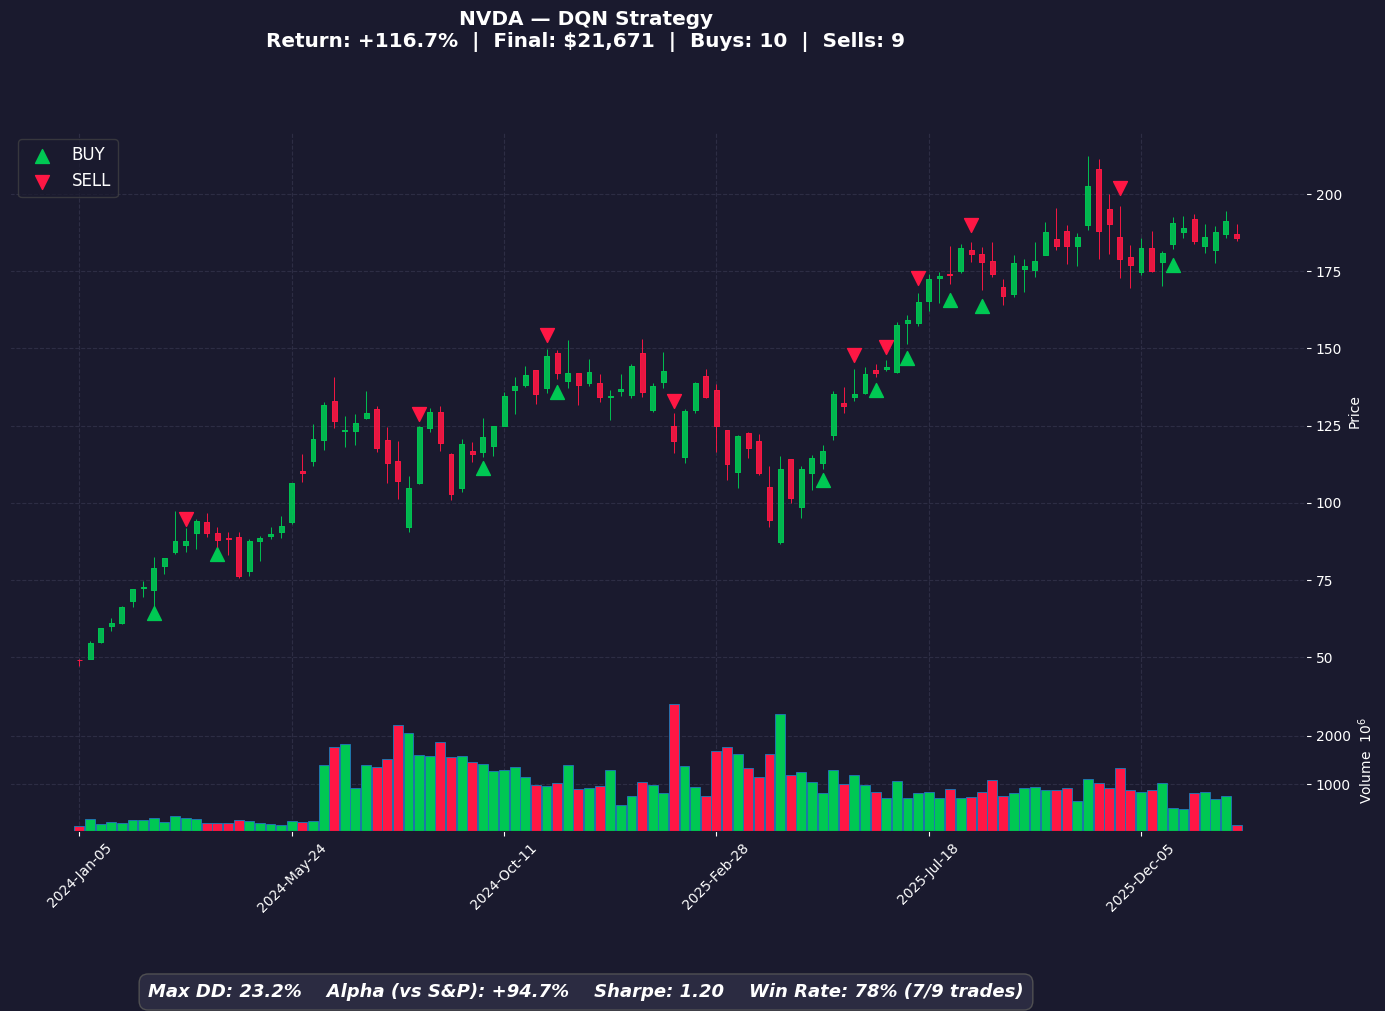

### NVDA — Trade Log (DQN)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_3411/1796150369.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-20,BUY,$69.41,143,"$9,926.18","$9,990.07"
2024-03-18,SELL,$88.41,143,"$12,642.70","$12,693.96"
2024-04-08,BUY,$87.09,145,"$12,627.93","$12,681.33"
2024-08-19,SELL,$129.95,145,"$18,842.08","$18,876.63"
2024-09-30,BUY,$121.40,155,"$18,816.87","$18,857.82"
2024-11-11,SELL,$145.21,155,"$22,507.73","$22,526.17"
2024-11-18,BUY,$140.10,160,"$22,416.46","$22,503.75"
2025-02-03,SELL,$116.63,160,"$18,660.61","$18,729.24"
2025-05-12,BUY,$122.98,152,"$18,692.62","$18,710.55"
2025-06-02,SELL,$137.36,152,"$20,877.98","$20,875.03"


In [168]:
plot_ticker('NVDA', method='DQN')

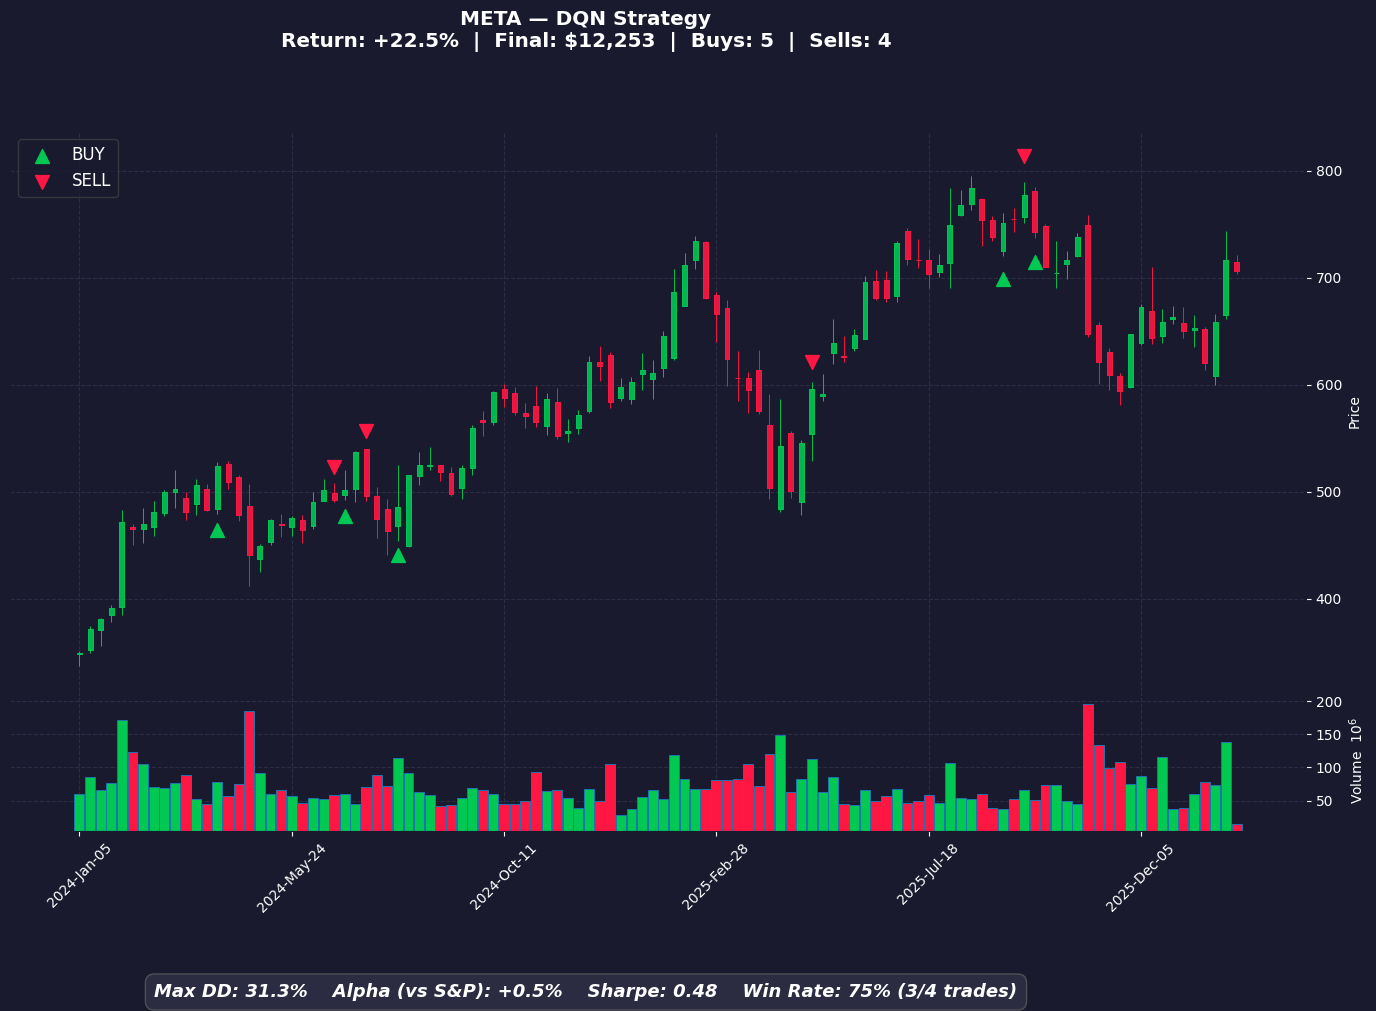

### META — Trade Log (DQN)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_3411/1796150369.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-04-01,BUY,$488.49,20,"$9,769.81","$9,990.23"
2024-06-24,SELL,$496.50,20,"$9,929.97","$10,140.46"
2024-07-01,BUY,$502.24,20,"$10,044.81","$10,130.41"
2024-07-15,SELL,$493.76,20,"$9,875.24","$9,950.96"
2024-08-05,BUY,$473.43,20,"$9,468.61","$9,941.49"
2025-05-05,SELL,$597.93,20,"$11,958.54","$12,419.46"
2025-09-02,BUY,$734.01,16,"$11,744.17","$12,407.72"
2025-09-22,SELL,$764.54,16,"$12,232.64","$12,883.95"
2025-09-29,BUY,$742.80,17,"$12,627.56","$12,871.33"


In [169]:
plot_ticker('META', method='DQN')

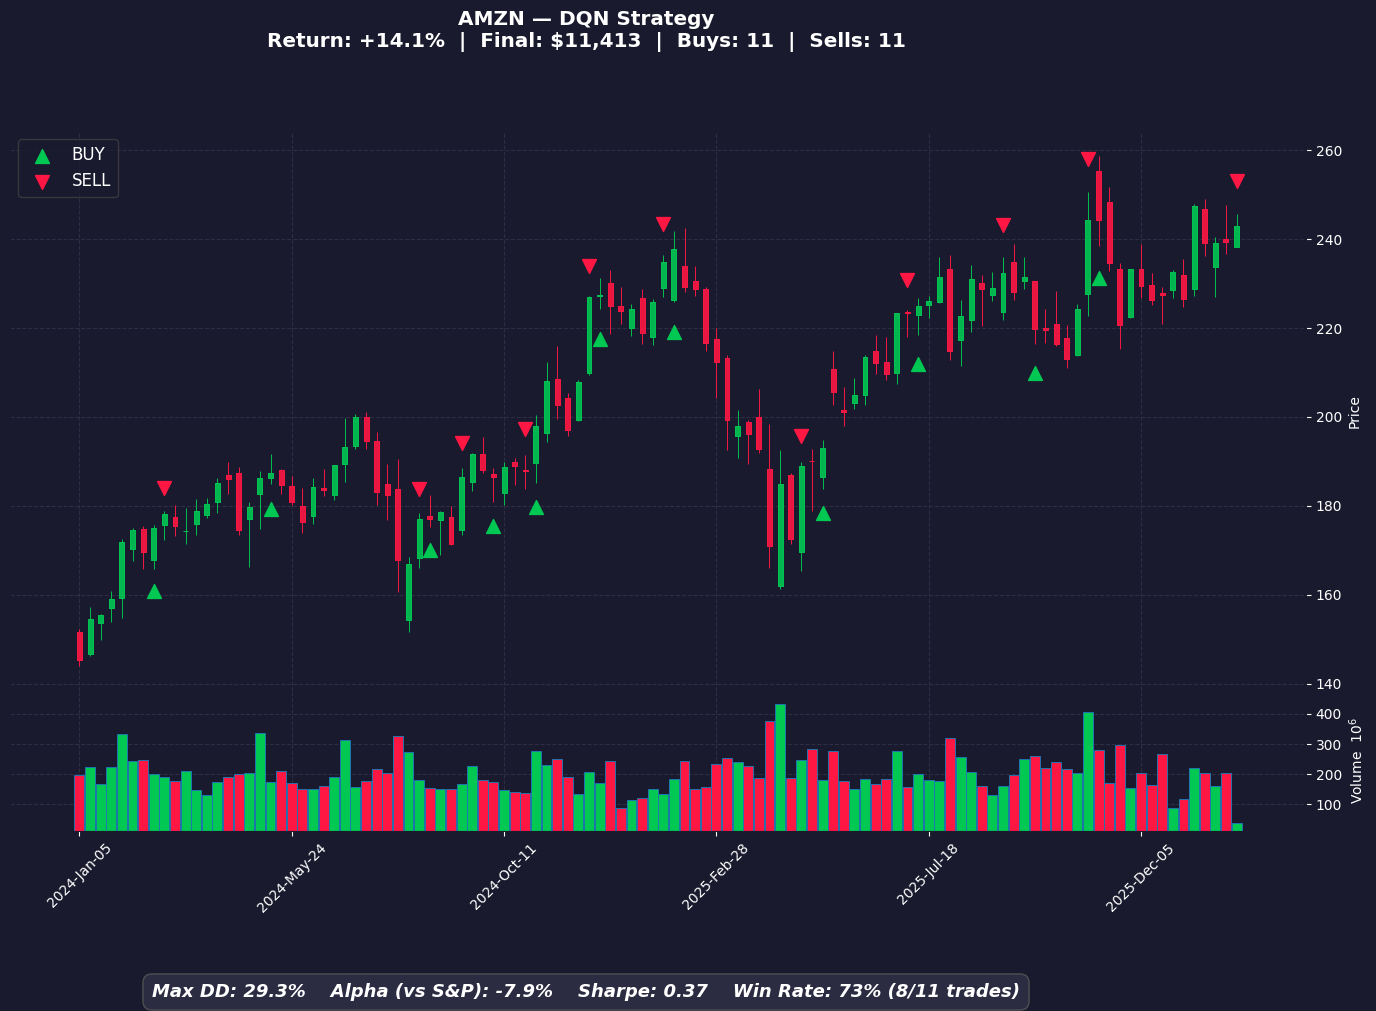

### AMZN — Trade Log (DQN)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_3411/1796150369.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-26,BUY,$174.73,57,"$9,959.61","$9,990.04"
2024-03-04,SELL,$177.58,57,"$10,122.06","$10,142.37"
2024-05-13,BUY,$186.57,54,"$10,074.78","$10,132.29"
2024-08-19,SELL,$178.22,54,"$9,623.88","$9,671.77"
2024-08-26,BUY,$175.50,55,"$9,652.50","$9,662.12"
2024-09-16,SELL,$184.89,55,"$10,168.95","$10,168.40"
2024-10-07,BUY,$180.80,56,"$10,124.80","$10,158.27"
2024-10-28,SELL,$188.39,56,"$10,549.84","$10,572.76"
2024-11-04,BUY,$195.78,53,"$10,376.34","$10,562.39"
2024-12-09,SELL,$226.09,53,"$11,982.77","$12,156.83"


In [170]:
plot_ticker('AMZN', method='DQN')

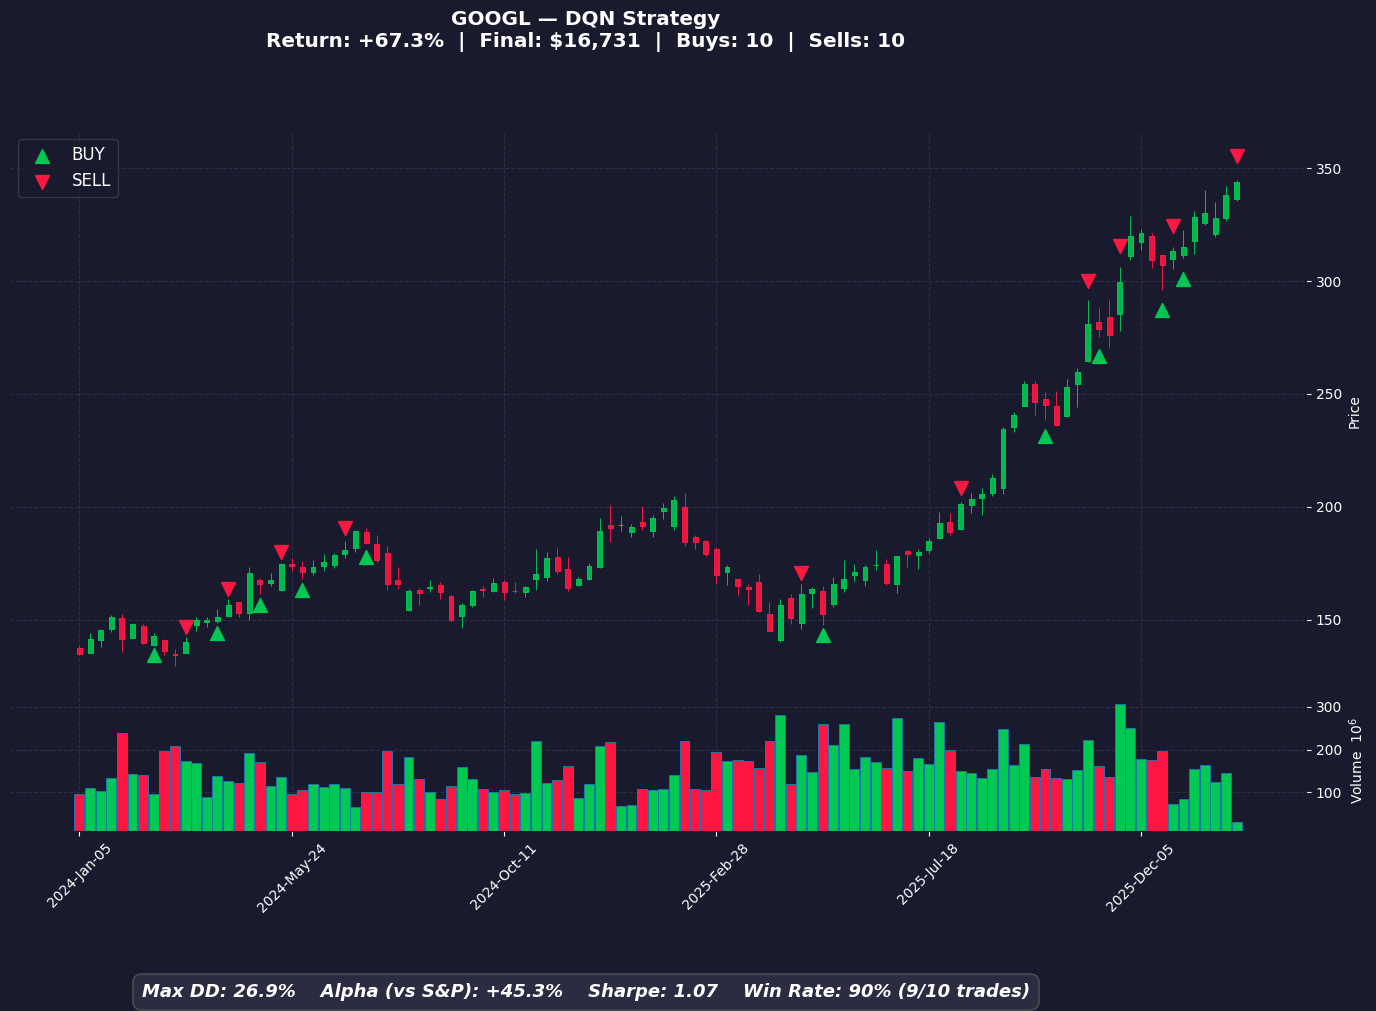

### GOOGL — Trade Log (DQN)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_3411/1796150369.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-20,BUY,$140.05,71,"$9,943.77","$9,990.06"
2024-03-18,SELL,$146.56,71,"$10,406.01","$10,441.89"
2024-04-08,BUY,$153.68,67,"$10,296.51","$10,431.59"
2024-04-15,SELL,$153.69,67,"$10,297.18","$10,421.96"
2024-05-06,BUY,$166.83,62,"$10,343.41","$10,411.62"
2024-05-20,SELL,$175.58,62,"$10,886.11","$10,943.44"
2024-05-28,BUY,$175.07,62,"$10,854.12","$10,932.58"
2024-07-01,SELL,$181.81,62,"$11,272.47","$11,339.67"
2024-07-15,BUY,$185.33,61,"$11,305.21","$11,328.36"
2025-04-28,SELL,$160.17,61,"$9,770.23","$9,783.61"


In [174]:
plot_ticker('GOOGL', method='DQN')

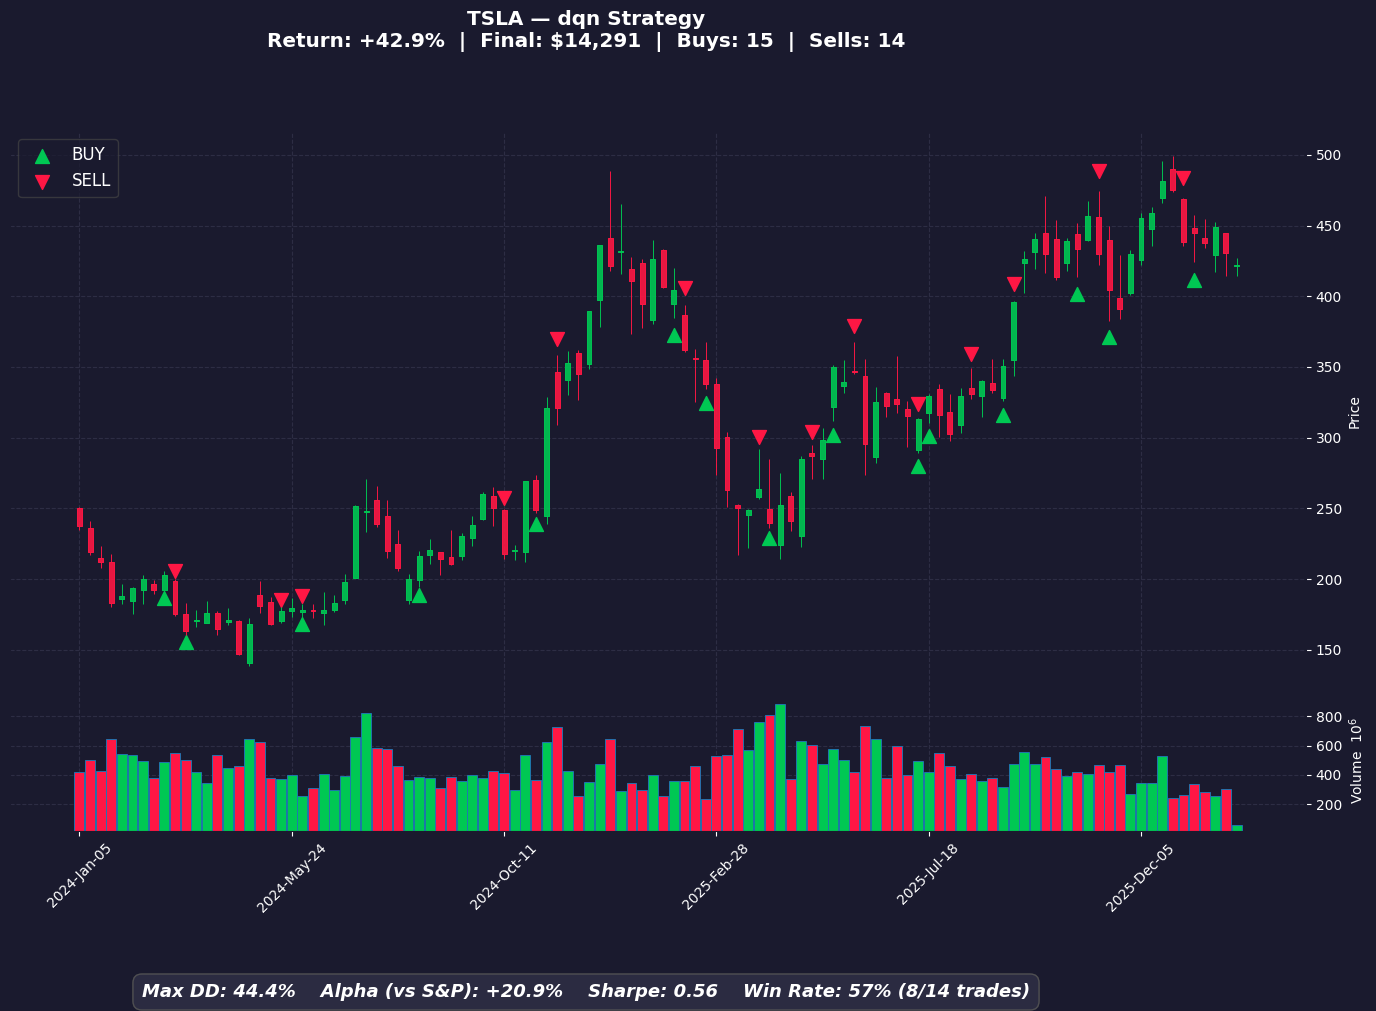

### TSLA — Trade Log (dqn)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_3411/1796150369.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-03-04,BUY,$188.14,53,"$9,971.42","$9,990.03"
2024-03-11,SELL,$177.77,53,"$9,421.81","$9,431.00"
2024-03-18,BUY,$173.80,54,"$9,385.20","$9,421.61"
2024-05-20,SELL,$174.95,54,"$9,447.30","$9,474.26"
2024-05-28,BUY,$176.75,53,"$9,367.75","$9,464.90"
2024-06-03,SELL,$176.29,53,"$9,343.37","$9,431.17"
2024-08-19,BUY,$222.72,42,"$9,354.24","$9,421.82"
2024-10-14,SELL,$219.16,42,"$9,204.72","$9,263.09"
2024-11-04,BUY,$242.84,38,"$9,227.92","$9,253.87"
2024-11-18,SELL,$338.74,38,"$12,872.12","$12,885.19"


In [172]:
plot_ticker('TSLA', method='dqn')

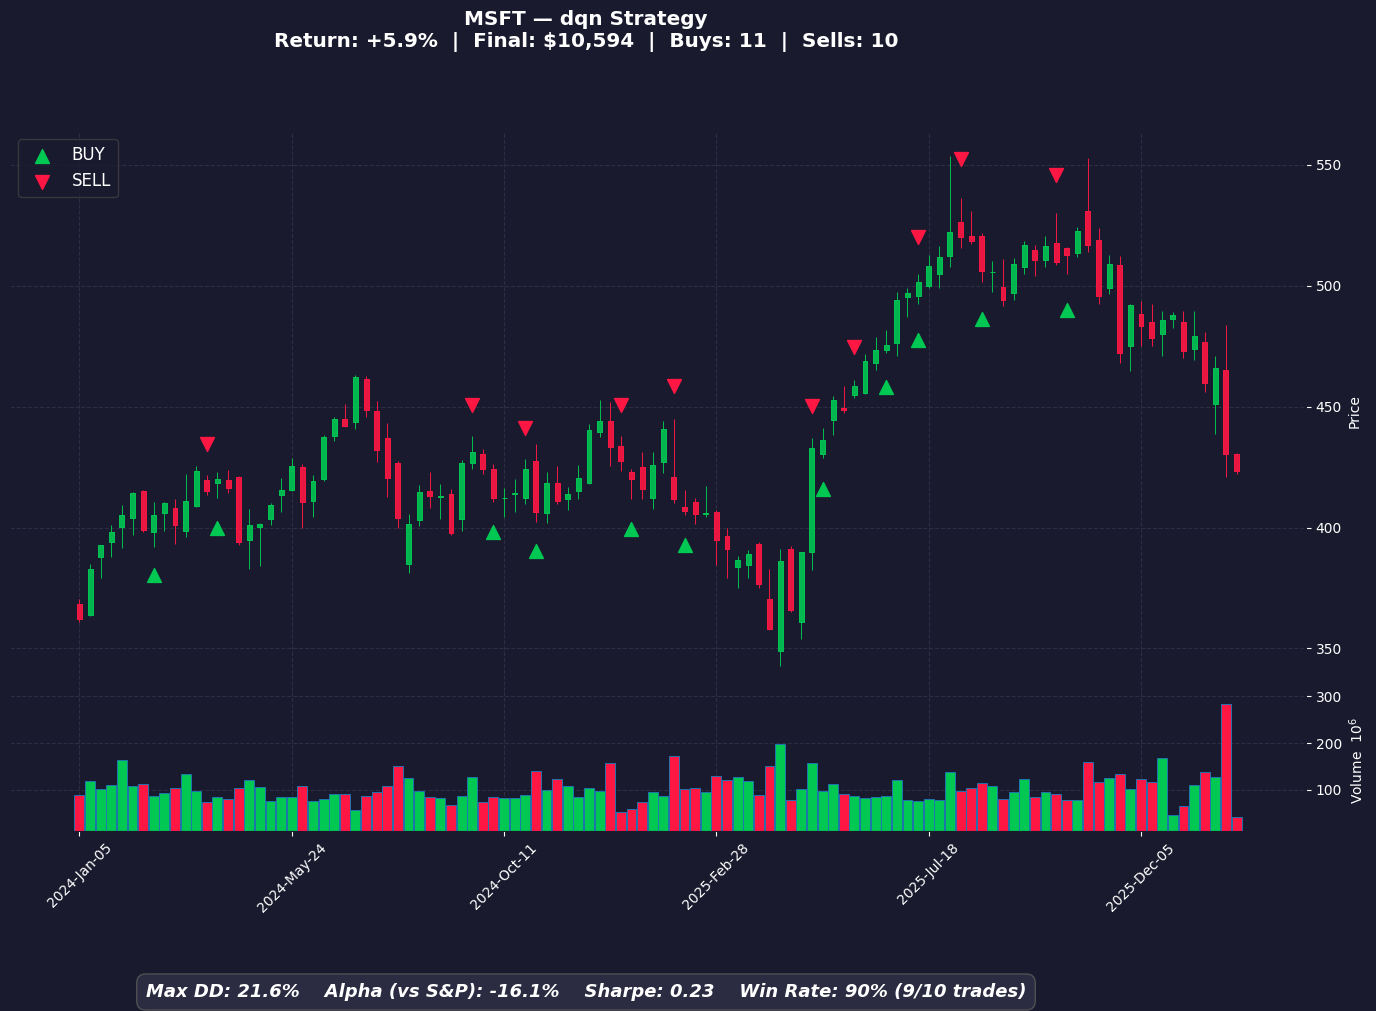

### MSFT — Trade Log (dqn)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_3411/1796150369.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-20,BUY,$397.62,25,"$9,940.42","$9,990.06"
2024-03-25,SELL,$417.43,25,"$10,435.72","$10,474.93"
2024-04-08,BUY,$419.14,24,"$10,059.28","$10,464.87"
2024-09-23,SELL,$429.46,24,"$10,307.15","$10,702.43"
2024-10-07,BUY,$405.72,26,"$10,548.67","$10,691.88"
2024-10-28,SELL,$422.61,26,"$10,987.84","$11,120.06"
2024-11-04,BUY,$404.65,27,"$10,925.50","$11,109.13"
2024-12-30,SELL,$421.71,27,"$11,386.21","$11,558.45"
2025-01-06,BUY,$424.71,27,"$11,467.15","$11,546.99"
2025-02-03,SELL,$407.90,27,"$11,013.40","$11,082.22"


In [173]:
plot_ticker('MSFT', method='dqn')

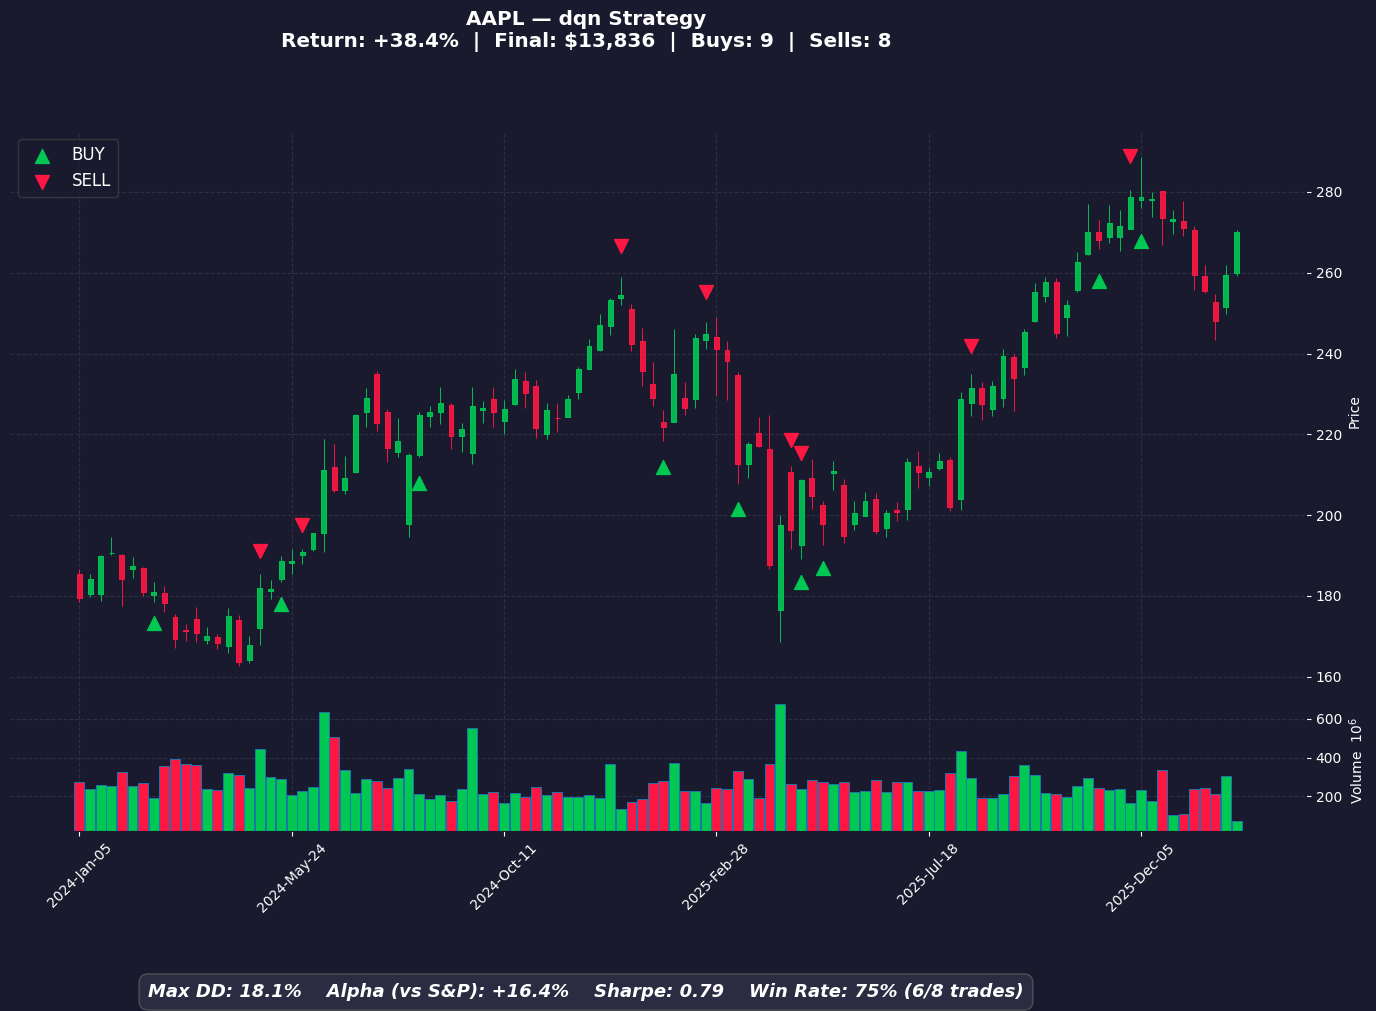

### AAPL — Trade Log (dqn)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_3411/1796150369.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-20,BUY,$180.10,55,"$9,905.71","$9,990.09"
2024-05-06,SELL,$180.25,55,"$9,913.89","$9,988.36"
2024-05-20,BUY,$189.77,52,"$9,867.86","$9,978.50"
2024-05-28,SELL,$188.72,52,"$9,813.63","$9,914.45"
2024-08-19,BUY,$224.64,44,"$9,884.25","$9,904.56"
2024-12-30,SELL,$251.08,44,"$11,047.65","$11,056.92"
2025-01-21,BUY,$221.65,49,"$10,861.04","$11,046.05"
2025-02-18,SELL,$243.65,49,"$11,939.07","$12,112.14"
2025-03-17,BUY,$213.29,56,"$11,944.03","$12,100.20"
2025-04-14,SELL,$201.84,56,"$11,303.29","$11,448.16"


In [178]:
plot_ticker('AAPL', method='dqn')

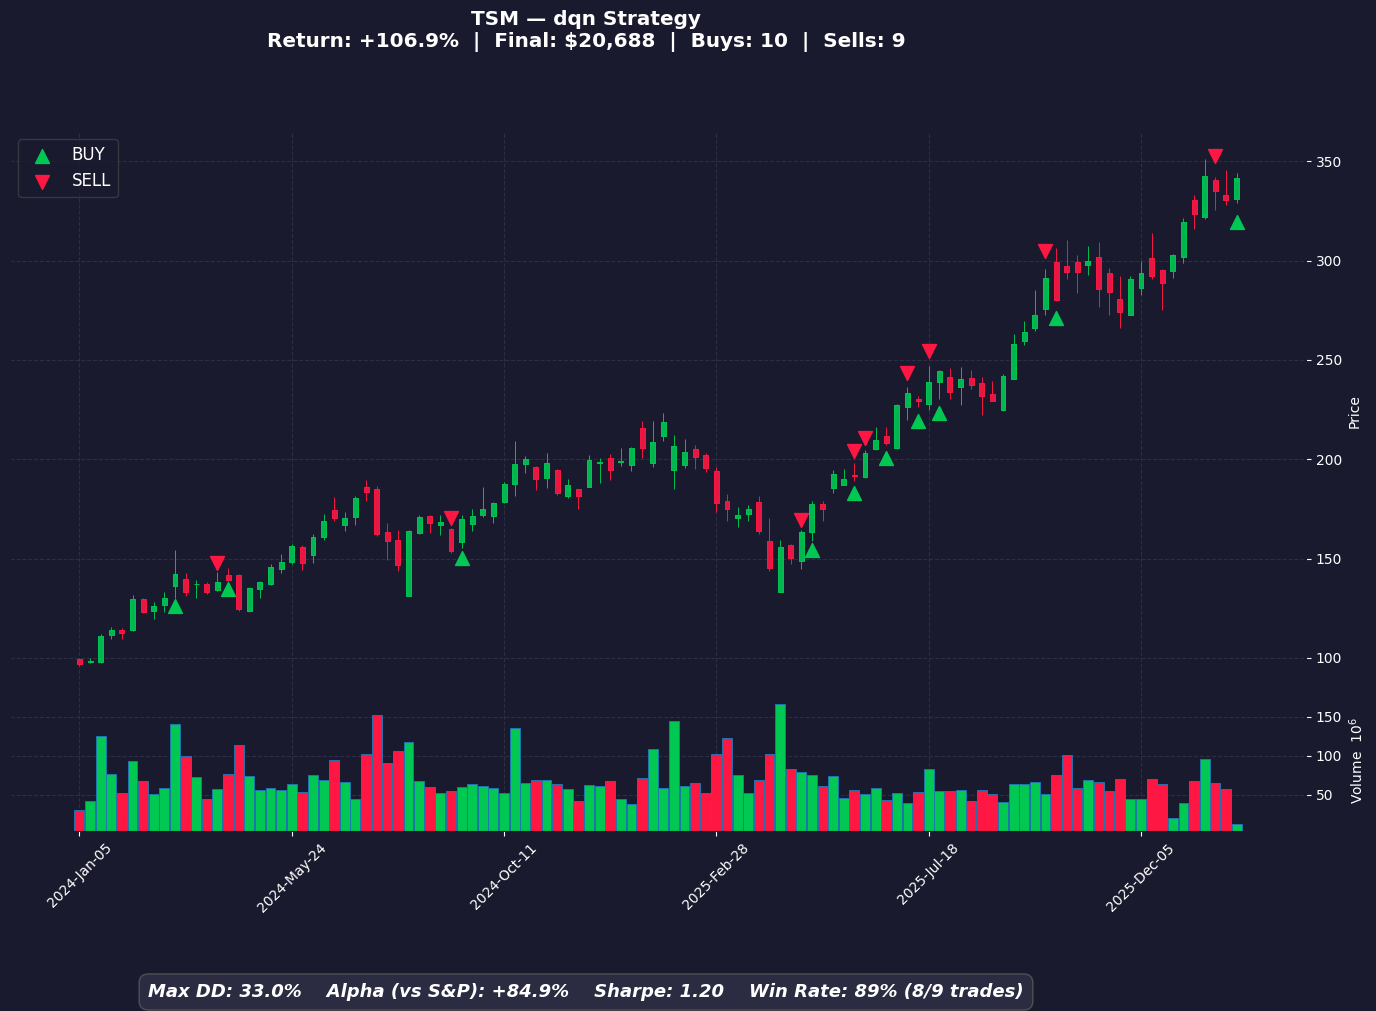

### TSM — Trade Log (dqn)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_3411/1796150369.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-03-11,BUY,$135.29,73,"$9,876.27","$9,990.12"
2024-04-08,SELL,$139.52,73,"$10,185.19","$10,288.86"
2024-04-15,BUY,$136.93,75,"$10,270.04","$10,278.59"
2024-09-09,SELL,$159.56,75,"$11,966.74","$11,963.33"
2024-09-16,BUY,$166.34,71,"$11,809.92","$11,951.52"
2025-04-28,SELL,$161.90,71,"$11,495.11","$11,625.21"
2025-05-05,BUY,$174.78,66,"$11,535.73","$11,613.67"
2025-05-27,SELL,$195.87,66,"$12,927.34","$12,992.35"
2025-06-02,BUY,$193.05,67,"$12,934.67","$12,979.42"
2025-06-09,SELL,$205.10,67,"$13,741.93","$13,772.93"


In [175]:
plot_ticker('TSM', method='dqn')

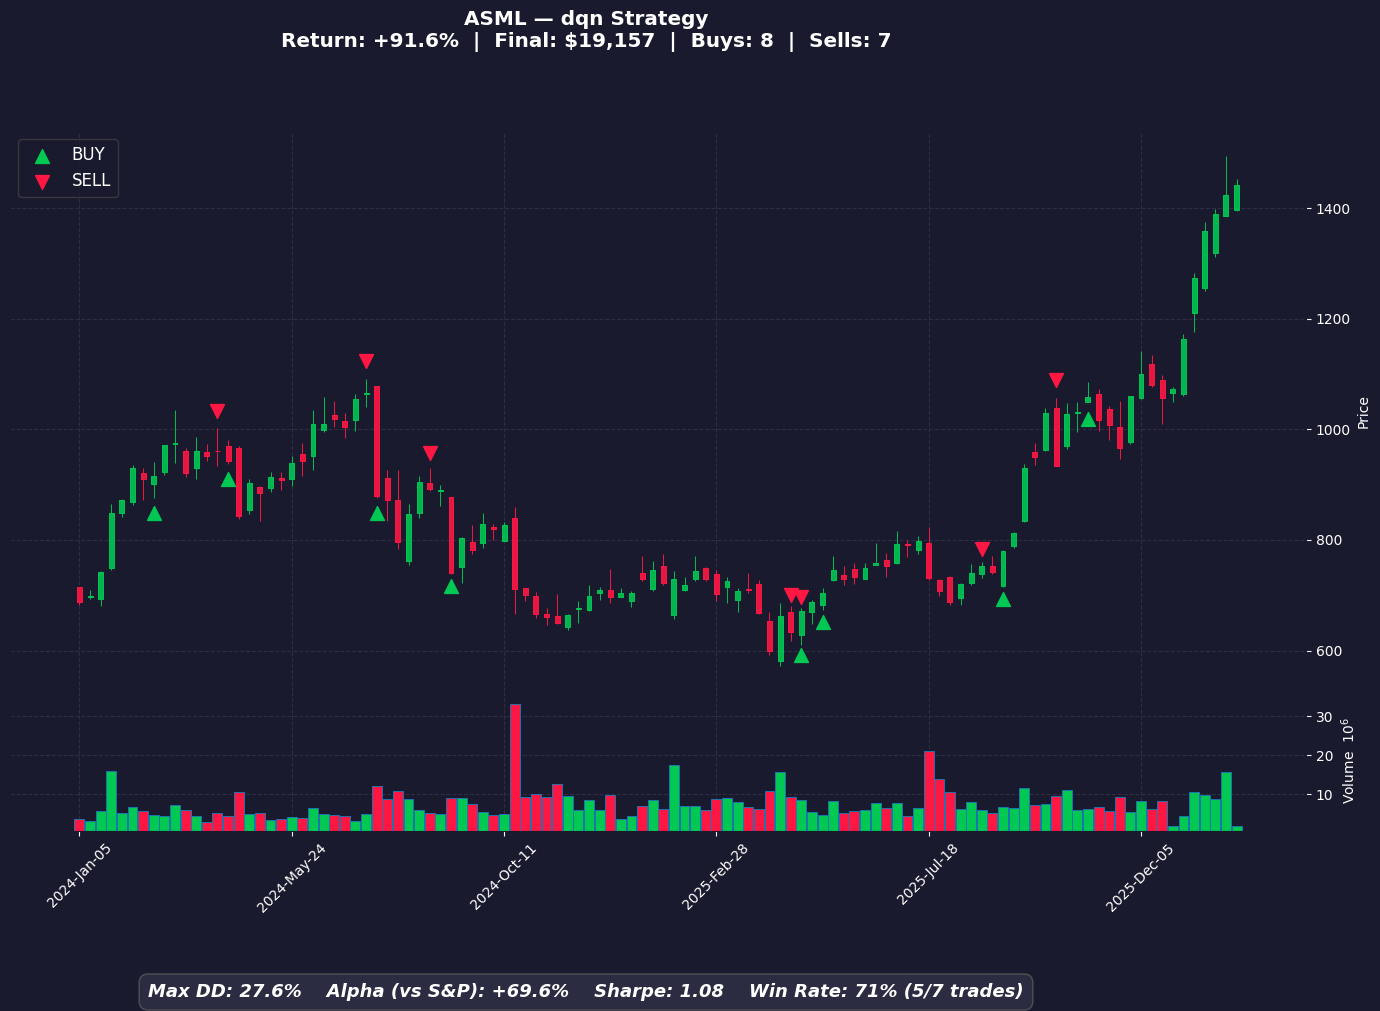

### ASML — Trade Log (dqn)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_3411/1796150369.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-26,BUY,$928.89,10,"$9,288.86","$9,990.71"
2024-04-01,SELL,$973.35,10,"$9,733.51","$10,425.62"
2024-04-15,BUY,$935.97,11,"$10,295.71","$10,415.33"
2024-07-15,SELL,"$1,044.76",11,"$11,492.37","$11,600.50"
2024-07-22,BUY,$924.56,12,"$11,094.75","$11,589.40"
2024-08-26,SELL,$869.28,12,"$10,431.34","$10,915.56"
2024-09-09,BUY,$737.91,14,"$10,330.72","$10,905.23"
2025-04-14,SELL,$666.29,14,"$9,328.06","$9,893.24"
2025-04-21,BUY,$618.58,15,"$9,278.71","$9,883.96"
2025-04-28,SELL,$669.86,15,"$10,047.91","$10,643.11"


In [176]:
plot_ticker('ASML', method='dqn')